# Group 28: Project 2 and the Final project

Carter Mitchell, Sydney Spacek

No AI tools were used.

# Project 2 Part 1

Implement a general continued fraction evaluator that takes $a_n$ and $b_n$ as functions of $n$
and a truncation depth $N$, using the backward recurrence.

In [1]:
# Code

# NOTE: a is treated as the numerator, b is treated as the denominator and the constant at the front.
# This is based directly on how the background is described in the problem statement.

import numpy as np

def continued_fraction_evaluator(a, b, depth_N, function_input=None):
    '''Uses backward recurrence to evalute the continued fraction given
    functions a and b as functions of n for truncation depth_N.'''
    # NOTE: Numpy functions are used to speed up computation speed
    
    # If the depth is 0, return b(0) immediately
    if depth_N == 0: return np.float64(b(0))
    
    # Constant evaluation
    if function_input == None:
        # Compute the first term at the bottom of the truncation, fraction_n = a(n)/b(n)
        fraction_n = np.divide(np.float64(a(depth_N)), np.float64(b(depth_N)), dtype=np.float64)
        for i in np.arange(depth_N-1, 0, -1):
            # Compute each term recursively from depth_N-1 backwards to 1
            fraction_n = np.divide(np.float64(a(i)), np.float64(b(i) + fraction_n), dtype=np.float64)
        # Then add the 0th term separately
        fraction_n = np.add(fraction_n, np.float64(b(0)))
        return fraction_n
    
    # Function evaluation with input x
    if function_input != None:
        # Compute the first term at the bottom of the truncation, fraction_n = a(n)/b(n)
            fraction_n = np.divide(np.float64(a(depth_N, function_input)), np.float64(b(depth_N, function_input)), dtype=np.float64)
            for i in np.arange(depth_N-1, 0, -1):
                # Compute each term recursively from depth_N-1 backwards to 1
                fraction_n = np.divide(np.float64(a(i, function_input)), np.float64(b(i, function_input) + fraction_n), dtype=np.float64)
            # Then add the 0th term separately
            fraction_n = np.add(fraction_n, np.float64(b(0, function_input)))
            return fraction_n

# Project 2 Part 2

Implement at least 5 constants with continued fraction formulas, for example $\pi$, $e$, $\sqrt{2}$,
the golden ratio, $\ln{2}$, $\zeta (2)$, $\zeta (3)$ and Catalan’s constant. Use the sources and cite the source of every formula you use.

In [2]:
# Code

import numpy as np
import sympy as sp

G = sp.S.Catalan.n(20) # Cataln's constant G up to 20 decimal places

N = 10_000 # keep depth at or below 10_000

# First Constant: 4/np.pi
# Wikipedia. William Brouncker, 2nd Viscount Brouncker, section “Brouncker’s formula”.
# https://en.wikipedia.org/wiki/William_Brouncker,_2nd_Viscount_Brouncker
def first_constant_a(i):
    if i == 1: return 1
    else: return (2*(i-2)+1)**2
def first_constant_b(i):
    if i == 0: return 0
    elif i == 1: return 1
    else: return 2

print(f"Depth: {N}")
first_constant = continued_fraction_evaluator(first_constant_a, first_constant_b, N)
print(f"First Constant:  {first_constant}, 4/np.pi:         {4/np.pi}")

# Second Constant: np.e
# J. Baez (2020). Three Phases of Continued Fraction Theory. The n-Category Café,
# September 6, 2020. https://golem.ph.utexas.edu/category/2020/09/five_levels_of_continued_fract.html

def second_constant_a(i): return 1
def second_constant_b(i):
    if i == 0: return 2
    elif i % 3 == 0 or i % 3 == 1: return 1
    else: return 2*(i+1)/3
    
second_constant = continued_fraction_evaluator(second_constant_a, second_constant_b, N)
print(f"Second Constant: {second_constant}, np.e:            {np.e}")

# Third Constant: 30/(np.pi**2)
# The Ramanujan Machine. Results (with links to results for π, e, ln 2, ζ(2), ζ(3) and Catalan’s
# constant). https://ramanujanmachine.com/results/

def third_constant_a(i): return i**4
def third_constant_b(i): return 11*i*(i+1)+3

third_constant = continued_fraction_evaluator(third_constant_a, third_constant_b, N)
print(f"Third Constant:  {third_constant}, 30/(np.pi**2):   {30/(np.pi**2)}")

# Fourth Constant: 1/(2*G), where G is Catalan's constant as evaluated from SymPy
# The Ramanujan Machine. Results (with links to results for π, e, ln 2, ζ(2), ζ(3) and Catalan’s
# constant). https://ramanujanmachine.com/results/
# https://ramanujanmachine.com/wp-content/uploads/2020/06/catalan.pdf 

def fourth_constant_a(i): return -2*i**4
def fourth_constant_b(i): return 3*i**2+3*i+1

fourth_constant = continued_fraction_evaluator(fourth_constant_a, fourth_constant_b, N)
print(f"Fourth Constant: {fourth_constant},  1/(2*G):         {1/(2*G)}")

# Fifth Constant: 1/(1-np.log(2))
# The Ramanujan Machine. Results (with links to results for π, e, ln 2, ζ(2), ζ(3) and Catalan’s
# constant). https://ramanujanmachine.com/results/
# https://ramanujanmachine.com/wp-content/uploads/2020/06/other.pdf

def fifth_constant_a(i): return -2*(i**2)*(i+1)**2
def fifth_constant_b(i): return 3*(i**2)+7*i+4

fifth_constant = continued_fraction_evaluator(fifth_constant_a, fifth_constant_b, N)
print(f"Fifth Constant:  {fifth_constant},  1/(1-np.log(2)): {1/(1-np.log(2))}")

print("\nDo not mind overflow errors.\n")

Depth: 10000
First Constant:  0.7853731633975107, 4/np.pi:         1.2732395447351628
Second Constant: 2.7182818284590455, np.e:            2.718281828459045
Third Constant:  3.0396355092701333, 30/(np.pi**2):   3.0396355092701333
Fourth Constant: 0.545872031851953,  1/(2*G):         0.54587203185195305073
Fifth Constant:  3.258891353270929,  1/(1-np.log(2)): 3.258891353270929

Do not mind overflow errors.



# Project 2 Part 3

Implement at least 5 functions with continued fraction formulas, for example $e^{x}$, $\ln{1 +
x}$, $\arctan{x}$, $\tan{x}$, $\tanh{x}$ and $\sqrt{1+x}$, and cite your sources.

In [3]:
# Code

import numpy as np

N = 10_000 # keep depth at or below 10_000
x = 7

# First Function: np.e**x
# Wikipedia. Euler's continued fraction formula, section “The exponential function”.
# https://en.wikipedia.org/wiki/Euler%27s_continued_fraction_formula

def first_function_a(i,x):
    if i == 1: return 1
    else: return -x/(i-1)
def first_function_b(i,x):
    if i == 0: return 0
    elif i == 1: return 1
    else: return 1+x/(i-1)

print(f"Depth: {N}, x: {x}")
first_function = continued_fraction_evaluator(first_function_a, first_function_b, N, x)
print(f"First Function:  {first_function}, np.e**x:    {np.exp(x)}")

# Second Function: np.sin(x)
# Wikipedia. Euler's continued fraction formula, section “The trigonometric functions”.
# https://en.wikipedia.org/wiki/Euler%27s_continued_fraction_formula

def second_function_a(i,x):
    if i == 1: return x
    elif i == 2: return x**2
    else: return (2*(i-2))*(2*(i-2)+1)*x**2
def second_function_b(i,x):
    if i == 0: return 0
    elif i == 1: return 1
    else: return (2*(i-1))*(2*(i-1)+1)-x**2

second_function = continued_fraction_evaluator(second_function_a, second_function_b, N, x)
print(f"Second Function: {second_function}, np.sin(x):  {np.sin(x)}")

# Third Function: np.sinh(x)
# Wikipedia. Euler's continued fraction formula, section “The hyperbolic functions”.
# https://en.wikipedia.org/wiki/Euler%27s_continued_fraction_formula

def third_function_a(i,x):
    if i == 1: return x
    elif i == 2: return -x**2
    else: return -(2*(i-2))*(2*(i-2)+1)*x**2
def third_function_b(i,x):
    if i == 0: return 0
    elif i == 1: return 1
    else: return (2*(i-1))*(2*(i-1)+1)+x**2

third_function = continued_fraction_evaluator(third_function_a, third_function_b, N, x)
print(f"Third Function:  {third_function},  np.sinh(x): {np.sinh(x)}")

# Fourth Function: np.tan(x)
# Paramand's Math Notes. Continued fraction expansion of tan(x).
# https://paramanands.blogspot.com/2011/04/continued-fraction-expansion-of-tanx.html

def fourth_function_a(i,x):
    if i == 1: return x
    else: return -x**2
def fourth_function_b(i,x):
    if i == 0: return 0
    else: return 2*i-1

fourth_function = continued_fraction_evaluator(fourth_function_a, fourth_function_b, N, x)
print(f"Fourth Function: {fourth_function}, np.tan(x):  {np.tan(x)}")

# Fifth Function: np.tanh(x)
# Wikipedia. Hyperbolic functions, section “Infinite products and continued fractions”.
# https://en.wikipedia.org/wiki/Hyperbolic_functions

def fifth_function_a(i,x): return 1
def fifth_function_b(i,x):
    if i == 0: return 0
    else: return (2*i-1)/x

fifth_function = continued_fraction_evaluator(fifth_function_a, fifth_function_b, N, x)
print(f"Fifth Function:  {fifth_function}, np.tanh(x): {np.tanh(x)}")

print("\nDo not mind overflow errors.\n")

Depth: 10000, x: 7
First Function:  1096.6331584285106, np.e**x:    1096.6331584284585
Second Function: 0.6569865987187934, np.sin(x):  0.6569865987187891


Third Function:  548.3161232732449,  np.sinh(x): 548.3161232732465
Fourth Function: 0.8714479827243188, np.tan(x):  0.8714479827243188
Fifth Function:  0.9999983369439447, np.tanh(x): 0.9999983369439447

Do not mind overflow errors.



# Project 2 Part 4

Compare each constant with a reference value from NumPy or SymPy, and report the
absolute and relative error in a table.

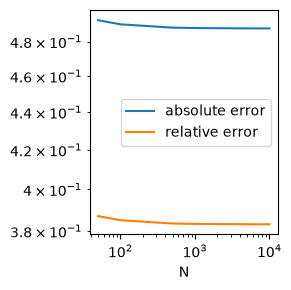

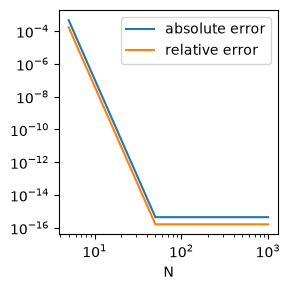

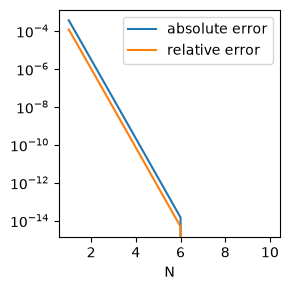

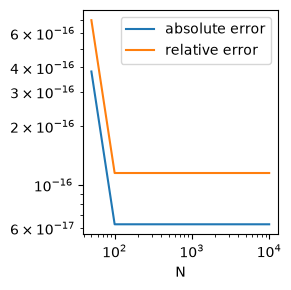

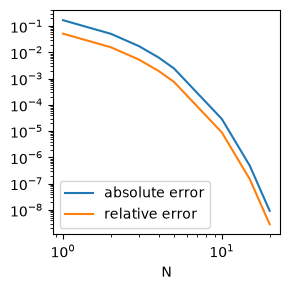

  constants        equations             Absolute error  \
0     first          np.pi/4                   0.487866   
1    second             np.e                        0.0   
2     third    30/(np.pi**2)                        0.0   
3    fourth          1/(2*G)  6.2792246445855792736e-17   
4     fifth  1/(1-np.log(2))                        0.0   

              relative error  
0                   0.383169  
1                        0.0  
2                        0.0  
3  1.1503107465100134020e-16  
4                        0.0  


In [11]:
#Code
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
import pandas as pd

#ab= |true-measured|
#rel= (|true-measured|)/true

# First Constant: 4/np.pi
aberr_list1 =[]
relerr_list1 =[]
N_list = [50,100,500,1000,5000,10000]
for n in N_list:
    first_constant = continued_fraction_evaluator(first_constant_a, first_constant_b, n)
    first_ab_err = np.abs((4/np.pi)-(first_constant))
    first_rel_err = (np.abs((4/np.pi)-(first_constant)))/(4/np.pi)
    aberr_list1.append(first_ab_err)
    relerr_list1.append(first_rel_err)
fig,ax= plt.subplots(figsize=(3,3))
ax.loglog(N_list, aberr_list1, label="absolute error")
ax.loglog(N_list, relerr_list1, label="relative error")
ax.set_xlabel("N")
ax.legend()
plt.tight_layout()
fig.savefig("plot1.png")
plt.show()

# Second Constant: np.e
aberr_list2 =[]
relerr_list2 =[]
N_list = [5,10,50,100,500,1000]
for n in N_list:
    second_constant = continued_fraction_evaluator(second_constant_a, second_constant_b, n)
    second_ab_err = np.abs((np.e)-(second_constant))
    second_rel_err = (np.abs((np.e)-(second_constant)))/(np.e)
    aberr_list2.append(second_ab_err)
    relerr_list2.append(second_rel_err)
fig,ax= plt.subplots(figsize=(3,3))
ax.loglog(N_list, aberr_list2, label="absolute error")
ax.loglog(N_list, relerr_list2, label="relative error")
ax.set_xlabel("N")
ax.legend()
plt.tight_layout()
fig.savefig("plot2.png")
plt.show()

# Third Constant: 30/(np.pi**2)
aberr_list3 =[]
relerr_list3 =[]
N_list = [1,2,3,4,5,6,10]
for n in N_list:
    third_constant = continued_fraction_evaluator(third_constant_a, third_constant_b, n)
    third_ab_err = np.abs((30/(np.pi**2))-(third_constant))
    third_rel_err = (np.abs((30/(np.pi**2))-(third_constant)))/(30/(np.pi**2))
    aberr_list3.append(third_ab_err)
    relerr_list3.append(third_rel_err)
fig,ax= plt.subplots(figsize=(3,3))
ax.semilogy(N_list, aberr_list3, label="absolute error")
ax.semilogy(N_list, relerr_list3, label="relative error")
ax.set_xlabel("N")
ax.legend()
plt.tight_layout()
fig.savefig("plot3.png")
plt.show()

# Fourth Constant: 1/(2*G), where G is Catalan's constant as evaluated from SymPy
aberr_list4 =[]
relerr_list4 =[]
N_list = [50,100,500,1000,5000,10000]
for n in N_list:
    fourth_constant = continued_fraction_evaluator(fourth_constant_a, fourth_constant_b, n)
    fourth_ab_err = np.abs((1/(2*G))-(fourth_constant))
    fourth_rel_err = (np.abs((1/(2*G))-(fourth_constant)))/(1/(2*G))
    aberr_list4.append(fourth_ab_err)
    relerr_list4.append(fourth_rel_err)
fig,ax= plt.subplots(figsize=(3,3))
ax.loglog(N_list, aberr_list4, label="absolute error")
ax.loglog(N_list, relerr_list4, label="relative error")
ax.set_xlabel("N")
ax.legend()
plt.tight_layout()
fig.savefig("plot4.png")
plt.show()

# Fifth Constant: 1/(1-np.log(2))
aberr_list5 =[]
relerr_list5 =[]
N_list = [1,2,3,4,5,10,15,20]
for n in N_list:
    fifth_constant = continued_fraction_evaluator(fifth_constant_a, fifth_constant_b, n)
    fifth_ab_err = np.abs((1/(1-np.log(2)))-(fifth_constant))
    fifth_rel_err = (np.abs((1/(1-np.log(2)))-(fifth_constant)))/(1/(1-np.log(2)))
    aberr_list5.append(fifth_ab_err)
    relerr_list5.append(fifth_rel_err)
fig,ax= plt.subplots(figsize=(3,3))
ax.loglog(N_list, aberr_list5, label="absolute error")
ax.loglog(N_list, relerr_list5, label="relative error")
ax.set_xlabel("N")
ax.legend()
plt.tight_layout()
fig.savefig("plot5.png")
plt.show()


#create table
#import pandas as pd

data = {
    "constants": ["first", "second", "third", "fourth", "fifth"],
    "equations": ["np.pi/4", "np.e", "30/(np.pi**2)", "1/(2*G)", "1/(1-np.log(2))"],
    "Absolute error": [first_ab_err, second_ab_err, third_ab_err, fourth_ab_err, fifth_ab_err],
    "relative error": [first_rel_err, second_rel_err, third_rel_err, fourth_rel_err, fifth_rel_err]
}

df = pd.DataFrame(data)
print(df)





# Project 2 Part 5

Plot each function against the corresponding built-in function in NumPy over a suitable
interval.

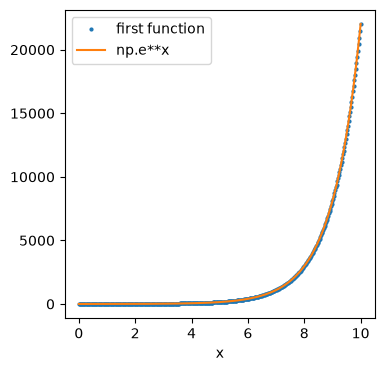

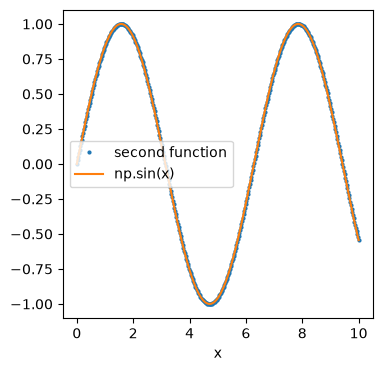

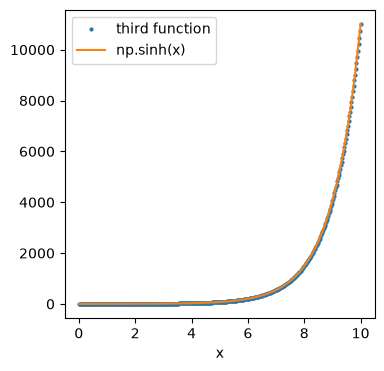

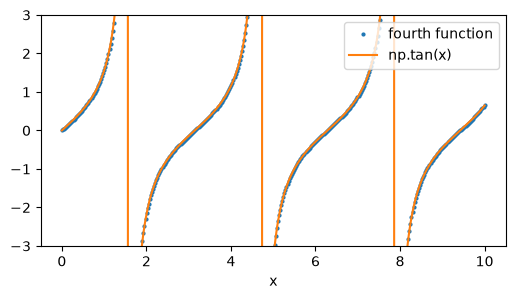

C:\Users\syd24\AppData\Local\Temp\ipykernel_25920\1131077338.py:77: RuntimeWarning: divide by zero encountered in scalar divide
  else: return (2*i-1)/x


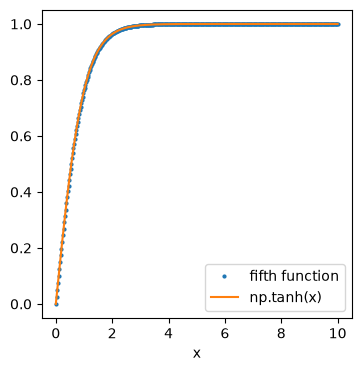

In [5]:
# Code

#{first_function}, np.e**x
xx1= np.linspace(0,10, 400)
tmp1_list = []
for x in xx1:
     tmp1_list.append(continued_fraction_evaluator(first_function_a, first_function_b, N, x))
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(xx1, tmp1_list,  "o", ms=2,  label="first function")
ax.plot(xx1, np.e**(xx1),  label="np.e**x")
ax.set_xlabel("x")
ax.legend()
plt.show()

#{second_function}, np.sin(x)
xx2= np.linspace(0,10, 400)
tmp2_list = []
for x in xx2:
     tmp2_list.append(continued_fraction_evaluator(second_function_a, second_function_b, N, x))
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(xx2, tmp2_list, "o", ms=2,   label="second function")
ax.plot(xx2, np.sin(xx2),  label="np.sin(x)")
ax.set_xlabel("x")
ax.legend()
plt.show()

#{third_function},  np.sinh(x)
xx3= np.linspace(0,10, 400)
tmp3_list = []
for x in xx3:
     tmp3_list.append(continued_fraction_evaluator(third_function_a, third_function_b, N, x))
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(xx3, tmp3_list, "o", ms=2,   label="third function")
ax.plot(xx3, np.sinh(xx3),  label="np.sinh(x)")
ax.set_xlabel("x")
ax.legend()
plt.show()

#{fourth_function}, np.tan(x)
xx4= np.linspace(0,10, 400)
tmp4_list = []
for x in xx4:
     tmp4_list.append(continued_fraction_evaluator(fourth_function_a, fourth_function_b, N, x))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(xx4, tmp4_list, "o", ms=2,  label="fourth function")
ax.plot(xx4, np.tan(xx4),  label="np.tan(x)")
ax.set_xlabel("x")
ax.set_ylim(-3,3)
ax.legend()
plt.show()

#{fifth_function}, np.tanh(x)
xx5= np.linspace(0,10, 400)
tmp5_list = []
for x in xx5:
     tmp5_list.append(continued_fraction_evaluator(fifth_function_a, fifth_function_b, N, x))
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(xx5, tmp5_list, "o", ms=2,   label="fifth function")
ax.plot(xx5, np.tanh(xx5),  label="np.tanh(x)")
ax.set_xlabel("x")
ax.legend()
plt.show()







# Project 2 Part 6

(Bonus) Also implement the forward recurrence and check that it agrees with the backward recurrence.

In [6]:
# Code
def continued_fraction_evaluator_forward(a, b, depth_N, function_input=None):

    # If the depth is 0, return b(0) immediately
    if depth_N == 0: return np.float64(b(0))
    
    # Constant evaluation
    if function_input == None:
        f_rec = []
        A_minus1 = 1
        B_minus1 = 0
        B_0 = 1
        A_0 = b(0)
        for i in np.arange(1,depth_N+1):
            A_n = np.add(np.multiply(b(i), A_0, dtype=np.float64), np.multiply(a(i), A_minus1, dtype=np.float64), dtype=np.float64)
            B_n = np.add(np.multiply(b(i), B_0, dtype=np.float64), np.multiply(a(i), B_minus1, dtype=np.float64), dtype=np.float64)
            x = np.divide(A_n, B_n, dtype=np.float64)
            f_rec = np.append(f_rec,x)
            A_minus1 = A_0
            B_minus1 = B_0
            A_0 = A_n
            B_0 = B_n
            i = i+1
        return f_rec[-1]
    if function_input != None:
        f_rec = []
        A_minus1 = 1
        B_minus1 = 0
        B_0 = 1
        A_0 = b(0,function_input)
        for i in np.arange(1,depth_N):
            A_n = np.add(np.multiply(b(i,function_input), A_0, dtype=np.float64), np.multiply(a(i, function_input), A_minus1, dtype=np.float64), dtype=np.float64)
            B_n = np.add(np.multiply(b(i,function_input), B_0, dtype=np.float64), np.multiply(a(i, function_input), B_minus1, dtype=np.float64), dtype=np.float64)
            x = np.divide(A_n, B_n, dtype=np.float64)
            f_rec = np.append(f_rec,x)
            A_minus1 = A_0
            B_minus1 = B_0
            A_0 = A_n
            B_0 = B_n
            i = i+1
        return f_rec[-1]
        
#constants
x=7
N=150
print(f"Depth: {N}")
first_constant = continued_fraction_evaluator_forward(first_constant_a, first_constant_b, N)
print(f"First Constant:  {first_constant}, np.pi/4:         {np.pi/4}")

second_constant = continued_fraction_evaluator_forward(second_constant_a, second_constant_b, N)
print(f"Second Constant: {second_constant}, np.e:            {np.e}")

third_constant = continued_fraction_evaluator_forward(third_constant_a, third_constant_b, N)
print(f"Third Constant:  {third_constant}, 30/(np.pi**2):   {30/(np.pi**2)}")

fourth_constant = continued_fraction_evaluator_forward(fourth_constant_a, fourth_constant_b, N)
print(f"Fourth Constant: {fourth_constant},  1/(2*G):         {1/(2*G)}")

fifth_constant = continued_fraction_evaluator_forward(fifth_constant_a, fifth_constant_b, N)
print(f"Fifth Constant:  {fifth_constant},  1/(1-np.log(2)): {1/(1-np.log(2))}")


#functions
x=4
N=50
print(f"Depth: {N}, x: {x}")
first_function = continued_fraction_evaluator_forward(first_function_a, first_function_b, N, x)
print(f"First Function:  {first_function}, np.e**x:    {np.exp(x)}")

second_function = continued_fraction_evaluator_forward(second_function_a, second_function_b, N, x)
print(f"Second Function: {second_function}, np.sin(x):  {np.sin(x)}")

third_function = continued_fraction_evaluator_forward(third_function_a, third_function_b, N, x)
print(f"Third Function:  {third_function},  np.sinh(x): {np.sinh(x)}")

fourth_function = continued_fraction_evaluator_forward(fourth_function_a, fourth_function_b, N, x)
print(f"Fourth Function: {fourth_function}, np.tan(x):  {np.tan(x)}")

fifth_function = continued_fraction_evaluator_forward(fifth_function_a, fifth_function_b, N, x)
print(f"Fifth Function:  {fifth_function}, np.tanh(x): {np.tanh(x)}")






Depth: 150
First Constant:  0.7837315152482716, np.pi/4:         0.7853981633974483
Second Constant: 2.7182818284590446, np.e:            2.718281828459045
Third Constant:  nan, 30/(np.pi**2):   3.0396355092701333
Fourth Constant: nan,  1/(2*G):         0.54587203185195305073
Fifth Constant:  nan,  1/(1-np.log(2)): 3.258891353270929
Depth: 50, x: 4
First Function:  54.59815003314428, np.e**x:    54.598150033144236
Second Function: -0.7568024953079285, np.sin(x):  -0.7568024953079282
Third Function:  27.28991719712775,  np.sinh(x): 27.289917197127753
Fourth Function: 1.1578212823495768, np.tan(x):  1.1578212823495777
Fifth Function:  0.999329299739068, np.tanh(x): 0.999329299739067


C:\Users\syd24\AppData\Local\Temp\ipykernel_25920\837013536.py:15: RuntimeWarning: overflow encountered in multiply
  A_n = np.add(np.multiply(b(i), A_0, dtype=np.float64), np.multiply(a(i), A_minus1, dtype=np.float64), dtype=np.float64)
C:\Users\syd24\AppData\Local\Temp\ipykernel_25920\837013536.py:16: RuntimeWarning: overflow encountered in multiply
  B_n = np.add(np.multiply(b(i), B_0, dtype=np.float64), np.multiply(a(i), B_minus1, dtype=np.float64), dtype=np.float64)
C:\Users\syd24\AppData\Local\Temp\ipykernel_25920\837013536.py:17: RuntimeWarning: invalid value encountered in divide
  x = np.divide(A_n, B_n, dtype=np.float64)
C:\Users\syd24\AppData\Local\Temp\ipykernel_25920\837013536.py:15: RuntimeWarning: invalid value encountered in add
  A_n = np.add(np.multiply(b(i), A_0, dtype=np.float64), np.multiply(a(i), A_minus1, dtype=np.float64), dtype=np.float64)
C:\Users\syd24\AppData\Local\Temp\ipykernel_25920\837013536.py:16: RuntimeWarning: invalid value encountered in add
  B_n =